# A classification algorithm: *k*-Nearest Neighbors

![](images/KnnClassification.svg)

The test sample should be classified to blue squares or red triangles. Which one is it? For $k=3$, it's red; for $k=5$, it's blue.

Image from: [Wikipedia](https://upload.wikimedia.org/wikipedia/commons/e/e7/KnnClassification.svg)

*Algorithm*

- Consider $k$ neighbors of a test data point. 
- If $k>1$, use voting to assign a label. 

*Model complexity for $k$-NN model*

- When $k$ small
  - The model makes predictions based on the nearest individual training data point. 
  - This leads to a very fine-grained decision boundary that can adapt closely to the training data, even capturing noise.
  - Each training point essentially has its own "influence zone," making the model highly flexible but prone to overfitting.

- When $k$ is large:
  - The model averages the influence of multiple neighbors to make predictions.
  - This results in a smoother decision boundary that is less sensitive to individual points, making the model more **generalized** and less prone to overfitting.


## How to measure distance?

- The distance measure (or metric) decides the performance of *k*-NN classifier.
- A common choice is the Minkowski distance of order $p$: $\text{dist}(\mathbf{x},\mathbf{z}) = \left( \sum\limits_{r = 1}^{d}|x_{r} - z_{r}|^{p} \right)^{1/p}$ (in $d$ dimensions)
  - $p = 1$: Manhattan distance
  - $p = 2$: Euclidean distance

### Best constant predictor

- A baseline classifier we should always be able to beat.
- The constant classifier always predicts the same value, regardless of the input.
  - For classification, the best constant is the most common label in the training set.
  - This is also what $k$-NN reduces to when $k = n$.

## First example: Iris

In [44]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import datasets
from sklearn.neighbors import KNeighborsClassifier

plt.style.use("ggplot")
plt.rcParams["figure.dpi"] = 100
font = {"family": "sans-serif", "size": 12}

mpl.rc("font", **font)

# 

## Van Gogh

https://en.wikipedia.org/wiki/Iris_(plant)#/media/File:VanGoghIrises2.jpg


![](images/VanGoghIrises2.jpg)

![300](images/iris.png)

https://scikit-learn.org/stable/datasets/toy_dataset.html#iris-plants-dataset

## IMPORTANT

- Always carefully study the data -- always! 
- Not only its statistical properties, but 
    - how it was collected
    - was it ethically done?
    - were the collectors biased? 
        - collecting data to support a favorite theory
        - societal bias (can be more insidious).
        - for example, read about [Eugenics](https://en.wikipedia.org/wiki/Eugenics)

In [45]:
iris_dataset = datasets.load_iris()

print(iris_dataset)
# for key in iris_dataset.keys():
#     print(key + "\n", iris_dataset[key])
#     # break

{'data': array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
     

In [46]:
# iris_dataset['target']

In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    iris_dataset["data"], iris_dataset["target"], test_size=.25, random_state=0)

print(len(X_train))
print(len(X_test))
print(len(y_train))
print(len(y_test))
print(X_train[:5])
print(y_train[:5])

112
38
112
38
[[5.9 3.  4.2 1.5]
 [5.8 2.6 4.  1.2]
 [6.8 3.  5.5 2.1]
 [4.7 3.2 1.3 0.2]
 [6.9 3.1 5.1 2.3]]
[1 1 2 0 2]


In [48]:
# Visual exploration. Important step in data analysis and ML!

name_map =  {0:'setosa', 1:'versicolor', 2:'virginica'}

# make pandas dataframes
iris_train = pd.DataFrame(X_train, columns=iris_dataset.feature_names)
iris_test = pd.DataFrame(X_test, columns=iris_dataset.feature_names)

# see the raw data, a bit more meaningfully
iris_train['Label']=pd.Series(y_train).map(name_map) # Add actual labels after converting them from numerical ones. I've used the data description from the last cell to get this information.
iris_train

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Label
0,5.9,3.0,4.2,1.5,versicolor
1,5.8,2.6,4.0,1.2,versicolor
2,6.8,3.0,5.5,2.1,virginica
3,4.7,3.2,1.3,0.2,setosa
4,6.9,3.1,5.1,2.3,virginica
...,...,...,...,...,...
107,4.9,3.1,1.5,0.1,setosa
108,6.3,2.9,5.6,1.8,virginica
109,5.8,2.7,4.1,1.0,versicolor
110,7.7,3.8,6.7,2.2,virginica


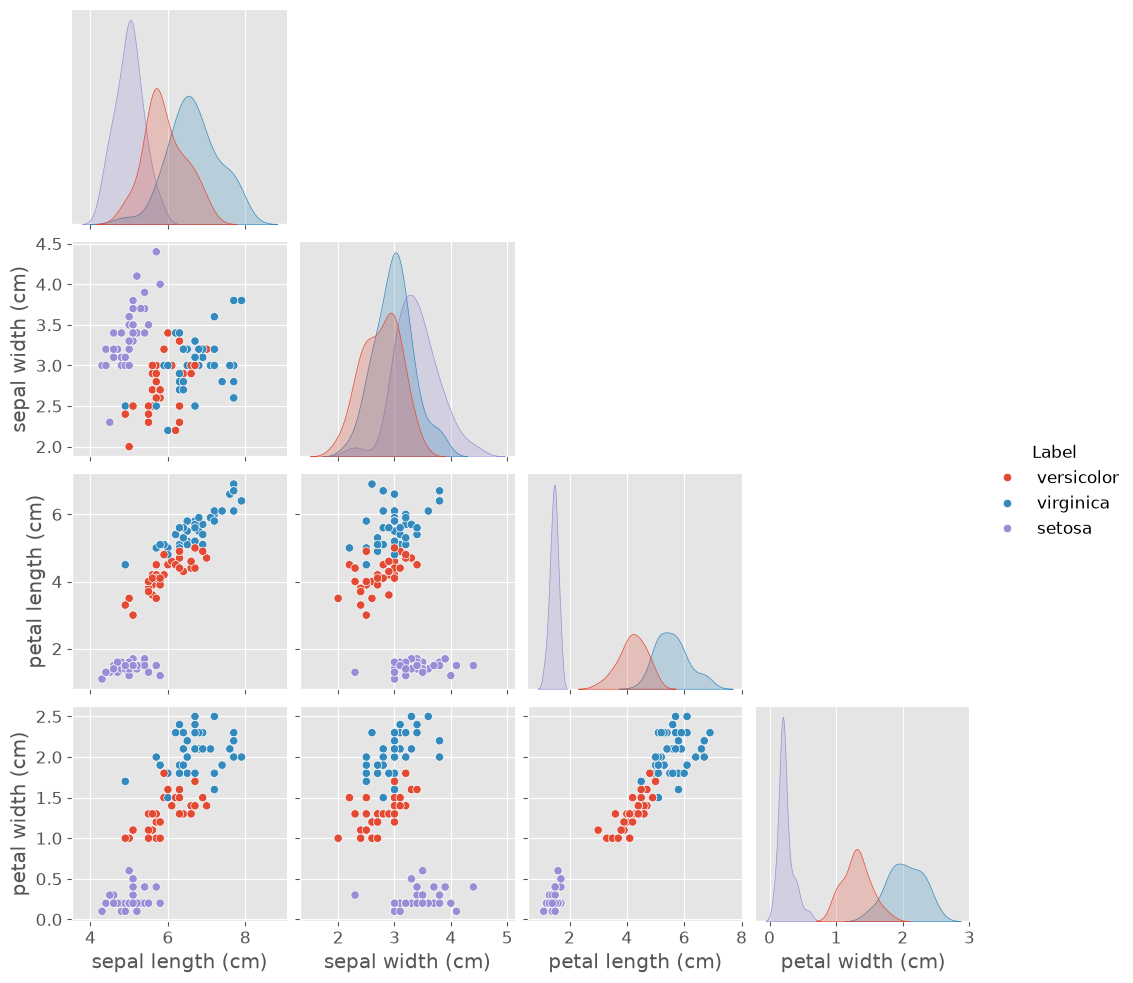

In [49]:
sns.pairplot(iris_train,hue='Label',corner=True,diag_kind='kde')
# sns.pairplot(iris_train,hue='Label',corner=True,diag_kind='hist')

# documentation: https://seaborn.pydata.org/generated/seaborn.pairplot.html. Seaborn is a very useful library for statistical analysis and plotting. Have a look!

In [50]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

X_new = np.array([[6.3,2.9,5.6,1.8]])
prediction = knn.predict(X_new)
print("Prediction:", prediction)
print("Predicted target name:", iris_dataset["target_names"][prediction])
pass;

Prediction: [2]
Predicted target name: ['virginica']


In [51]:
y_pred = knn.predict(X_test)
# X_test
print("Test set predictions:\n", y_pred)
print(y_test)
print("Test set predictions (with labels):\n", [name_map[i] for i in y_pred])
print(y_pred == y_test)
print("Test set score: {:.2f}".format(np.mean(y_pred == y_test))) # explicit computation
print("Test set score: {:.2f}".format(knn.score(X_test, y_test))) # same stuff, different way of computing

Test set predictions:
 [2 1 0 2 0 2 0 1 1 1 2 1 1 1 1 0 1 1 0 0 2 1 0 0 2 0 0 1 1 0 2 1 0 2 2 1 0
 2]
[2 1 0 2 0 2 0 1 1 1 2 1 1 1 1 0 1 1 0 0 2 1 0 0 2 0 0 1 1 0 2 1 0 2 2 1 0
 1]
Test set predictions (with labels):
 ['virginica', 'versicolor', 'setosa', 'virginica', 'setosa', 'virginica', 'setosa', 'versicolor', 'versicolor', 'versicolor', 'virginica', 'versicolor', 'versicolor', 'versicolor', 'versicolor', 'setosa', 'versicolor', 'versicolor', 'setosa', 'setosa', 'virginica', 'versicolor', 'setosa', 'setosa', 'virginica', 'setosa', 'setosa', 'versicolor', 'versicolor', 'setosa', 'virginica', 'versicolor', 'setosa', 'virginica', 'virginica', 'versicolor', 'setosa', 'virginica']
[ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True False]
Test set score: 0.97
Test set score: 0.97


## Second example: Breast cancer data

https://scikit-learn.org/stable/datasets/toy_dataset.html#breast-cancer-dataset

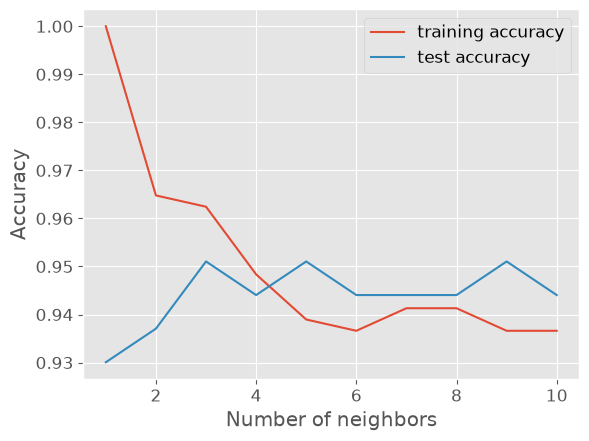

In [52]:
# code from Guido & Mueller

cancer = datasets.load_breast_cancer()

X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, stratify=cancer.target
)

# For the breast cancer dataset: cancer.target contains binary values (0 for malignant and 1 for benign). Suppose 62% of the samples are benign and 38% are malignant. Using `stratify=cancer.target` ensures that both the training and test sets maintain this same proportion of benign and malignant samples.

training_accuracy = []
test_accuracy = []
# try n_neighbors from 1 to 10
neighbors_settings = range(1, 11)

for n_neighbors in neighbors_settings:
    # build the model
    clf = KNeighborsClassifier(n_neighbors=n_neighbors)
    clf.fit(X_train, y_train)
    # record training set accuracy
    training_accuracy.append(clf.score(X_train, y_train))
    # record generalization accuracy
    test_accuracy.append(clf.score(X_test, y_test))

plt.plot(neighbors_settings, training_accuracy, label="training accuracy")
plt.plot(neighbors_settings, test_accuracy, label="test accuracy")
plt.ylabel("Accuracy")
plt.xlabel("Number of neighbors")
plt.legend()
pass;

## One issue with *k*-NN: the Curse of dimensionality

- *k*-NN assumes that similar -- i.e. neighboring -- points share similar labels. 
- In high dimensions, this assumption tends to break down: points drawn from a distribution rarely end up close together.
- Let's say we sample points uniformly at random inside the unit cube $[0,1]^d$, and check how much of the space is needed to capture the $k = 10$ nearest neighbors of a test point.
- Let $\ell$ be the edge length of the smallest hyper-cube containing all $k$ nearest neighbors. As the points are uniformly distributed:
$$
\ell^{d} \approx \frac{k}{n}, \qquad \ell \approx \left( \frac{k}{n} \right)^{1/d}
$$
- With $n = 1000$ and $k = 10$, $\ell$ grows quickly with $d$:

| $d$ | $\ell$ |
|---|---|
| 2 | 0.1 |
| 10 | 0.63 |
| 100 | 0.955 |


- As $d$ grows large, nearly the entire space is needed just to find the 10 nearest neighbors. This undermines the whole point of k-NN: those "neighbors" aren't actually close to the test point, so there's no good reason to expect they share its label.